# NC75379261 — DAS vs MH030 GP1

Corrected comparison for the June 18, 2026 event.

**Key point:** the June HDF5 row numbering is not the old physical channel numbering.  
We therefore **do not hard-code row 1278**. Instead, we take the physical receiver
location used for the April comparison (`ReferenceChannel = 1694`) and map it to
the correct June HDF5 `DataRow` using the event-specific channel-registration CSV.

Processing:

- DAS: QuantX HDF5, `diff=True`
- geophone: `SF.MH030.01.GP1`
- response removed to **VEL**
- filtered comparison: **5–40 Hz causal, non-zero-phase**
  `DASutils.bandpass2D_c(..., order=6, zerophase=False)`
- broadband comparison: **no final science bandpass**
- no relative time shift
- no normalization or amplitude fitting


In [43]:
from __future__ import annotations

import datetime
import os
from pathlib import Path
import sys

import dateutil.parser
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from obspy import UTCDateTime
from obspy.clients.fdsn import Client
from scipy.signal import detrend
from scipy.signal.windows import tukey


# =============================================================================
# CONFIG
# =============================================================================

# Locate the repository from either its root or notebooks/.
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "src/sbp_sat").is_dir() and (candidate / "scripts/safod").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from the project root or notebooks/.")

EVENT_ID = "NC75379261"

ORIGIN = UTCDateTime(
    "2026-06-18T21:04:42.290000Z"
)

DAS_FILE = Path(
    "/oak/stanford/groups/ettore88/data/SAFOD/SAFOD_events/"
    "SAFOD_QuantX-2026-06-18T210347Z.h5"
)

# Event-specific June HDF5-row -> physical cable registration.
CHANNEL_MAPPING_CSV = PROJECT_ROOT / Path(
    "results/events/20260618_75379261/real/"
    "channel_registration_qc/mapped_downleg_model_geometry.csv"
)

# SAME PHYSICAL receiver coordinate used for the April comparison.
TARGET_REFERENCE_CHANNEL = 1694.0

NETWORK = "SF"
STATION = "MH030"
LOCATION = "01"
GEOPHONE_CHANNEL = "GP1"

# If MH030 response metadata are still unavailable, use the known
# MH029 GP1 response provisionally, as in the October comparison workflow.
RESPONSE_FALLBACK_STATION = "MH029"
RESPONSE_FALLBACK_TIME = UTCDateTime(
    "2026-04-01T04:57:57.470000Z"
)

# Final science filter.
FMIN_HZ = 5.0
FMAX_HZ = 40.0
FILTER_ORDER = 6

# Only for stable response deconvolution.
# This is NOT the final 5-40 Hz science filter.
RESPONSE_PREFILT_HZ = (
    0.2,
    0.5,
    220.0,
    240.0,
)

EDGE_TAPER_FRACTION = 0.05
REQUEST_PAD_S = 20.0

# Plot limits only.
PLOT_TMIN_S = 0.25
PLOT_TMAX_S = 0.75
XTICK_STEP_S = 0.1

DAS_COLOR = "0.52"
GEO_COLOR = "#940025"

SAVE_FIGURES = True
OUTPUT_DIR = PROJECT_ROOT / Path(
    "results/events/20260618_75379261/compare/das_geophone_common_workflow"
)
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


In [44]:
# =============================================================================
# DASutils
# =============================================================================

DAS_UTILITIES_ROOT = Path(
    "/home/groups/ettore88/alina/packages/DAS-utilities"
)
DAS_UTILITIES_BUILD = DAS_UTILITIES_ROOT / "build"
DAS_UTILITIES_PYTHON = DAS_UTILITIES_ROOT / "python"

old_ld = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = (
    f"{old_ld}:{DAS_UTILITIES_BUILD}"
    if old_ld
    else str(DAS_UTILITIES_BUILD)
)

sys.path.insert(0, str(DAS_UTILITIES_BUILD))
sys.path.insert(0, str(DAS_UTILITIES_PYTHON))

import DASutils

NCEDC = Client(
    "https://service.ncedc.org"
)


# =============================================================================
# Helpers
# =============================================================================

def parse_beg_time(info):
    value = info["begTime"]

    if isinstance(value, datetime.datetime):
        dt = value
        if dt.tzinfo is None:
            dt = dt.replace(
                tzinfo=datetime.timezone.utc
            )
        return UTCDateTime(dt)

    dt = dateutil.parser.parse(str(value))

    if dt.tzinfo is None:
        dt = dt.replace(
            tzinfo=datetime.timezone.utc
        )

    return UTCDateTime(dt)


def detrend_demean(x):
    y = detrend(
        np.asarray(
            x,
            dtype=np.float64,
        ),
        type="linear",
    )
    return y - np.mean(y)


def edge_taper(x):
    y = np.asarray(
        x,
        dtype=np.float64,
    )

    return y * tukey(
        y.size,
        alpha=2.0 * EDGE_TAPER_FRACTION,
    )


def causal_bandpass(
    trace,
    fs_hz,
):
    """
    CAUSAL / NON-ZERO-PHASE 5-40 Hz filter.

    Single forward pass only:
        DASutils.bandpass2D_c(
            ...,
            order=6,
            zerophase=False,
        )

    No filtfilt, no backward pass, no delay correction.
    """

    x = np.ascontiguousarray(
        np.asarray(
            trace,
            dtype=np.float64,
        )[None, :]
    )

    y = DASutils.bandpass2D_c(
        x,
        FMIN_HZ,
        FMAX_HZ,
        1.0 / float(fs_hz),
        order=FILTER_ORDER,
        zerophase=False,
    )

    return np.asarray(
        y,
        dtype=np.float64,
    )[0]


def symmetric_ylim(ax, data):
    limit = 1.05 * float(
        np.nanmax(
            np.abs(data)
        )
    )

    if np.isfinite(limit) and limit > 0:
        ax.set_ylim(
            -limit,
            limit,
        )


In [45]:
# =============================================================================
# 1. Map physical channel 1694 -> correct June HDF5 DataRow
# =============================================================================

if not CHANNEL_MAPPING_CSV.exists():
    raise FileNotFoundError(
        f"June channel-registration CSV not found:\n"
        f"{CHANNEL_MAPPING_CSV}\n\n"
        "Run this notebook from the Elastic_das_project repository root."
    )

mapping = pd.read_csv(
    CHANNEL_MAPPING_CSV
)

if "DataRow" not in mapping.columns:
    raise RuntimeError(
        "Registration CSV has no DataRow column."
    )

if "ReferenceChannel" in mapping.columns:
    reference_column = "ReferenceChannel"
elif "Channel" in mapping.columns:
    # prepare_event's standardized mapped geometry uses Channel for the
    # stable physical reference-channel coordinate.
    reference_column = "Channel"
else:
    raise RuntimeError(
        "Registration CSV has neither ReferenceChannel nor Channel."
    )

reference_values = pd.to_numeric(
    mapping[reference_column],
    errors="raise",
).to_numpy(dtype=float)

data_rows = pd.to_numeric(
    mapping["DataRow"],
    errors="raise",
).to_numpy(dtype=float)

i_nearest = int(
    np.argmin(
        np.abs(
            reference_values
            - TARGET_REFERENCE_CHANNEL
        )
    )
)

MATCHED_REFERENCE_CHANNEL = float(
    reference_values[i_nearest]
)

DAS_DATA_ROW = int(
    round(
        data_rows[i_nearest]
    )
)

print("June receiver registration")
print("--------------------------")
print(
    "target physical channel :",
    TARGET_REFERENCE_CHANNEL,
)
print(
    "matched physical channel:",
    f"{MATCHED_REFERENCE_CHANNEL:.3f}",
)
print(
    "June HDF5 DataRow       :",
    DAS_DATA_ROW,
)

if "TVD_m" in mapping.columns:
    print(
        "TVD                     :",
        f"{float(mapping.iloc[i_nearest]['TVD_m']):.3f} m",
    )

print()
print(
    "NOTE: the cable turnaround row is NOT used as the comparison "
    "receiver unless it happens to map to physical channel 1694."
)


June receiver registration
--------------------------
target physical channel : 1694.0
matched physical channel: 1693.821
June HDF5 DataRow       : 1273
TVD                     : 2541.817 m

NOTE: the cable turnaround row is NOT used as the comparison receiver unless it happens to map to physical channel 1694.


In [46]:
# =============================================================================
# 2. Read QuantX DAS
#
# EXACT same reader convention as scripts/safod/prepare_event.py:
#   diff=True
#   median=True
#   system="OptaSense"
# =============================================================================

das_data, info = DASutils.readFile_HDF(
    [str(DAS_FILE)],
    0.01,
    500.0,
    verbose=1,
    diff=True,
    detrend=False,
    tapering=False,
    filter=False,
    median=True,
    desampling=False,
    nChbuffer=1000,
    system="OptaSense",
)

das_data = np.asarray(
    das_data,
    dtype=np.float64,
)

DAS_FS = float(
    info["fs"]
)

DAS_BEG = parse_beg_time(
    info
)

DAS_time_s = (
    float(
        DAS_BEG - ORIGIN
    )
    + np.arange(
        das_data.shape[1],
        dtype=np.float64,
    )
    / DAS_FS
)

if not (
    0 <= DAS_DATA_ROW < das_data.shape[0]
):
    raise IndexError(
        f"Mapped June DataRow {DAS_DATA_ROW} "
        f"outside data shape {das_data.shape}."
    )


# ------------------------------------------------------------------
# DAS UNITS
# ------------------------------------------------------------------
#
# Follow the project convention in prepare_event.py literally:
#
#   reader output * 1e3 = strain rate [nm/m/s]
#
# Therefore:
#
#   strain rate [um/m/s] = (reader output * 1e3) / 1e3
#
# Numerically this is simply the reader output.
# Writing it explicitly here avoids any hidden unit assumption.
# ------------------------------------------------------------------

das_rate_nm_per_m_per_s = (
    das_data[DAS_DATA_ROW]
    * 1.0e3
)

das_rate_um_per_m_per_s = (
    das_rate_nm_per_m_per_s
    / 1.0e3
)

das_full = edge_taper(
    detrend_demean(
        das_rate_um_per_m_per_s
    )
)

# CAUSAL / NON-ZERO-PHASE science branch.
das_causal = causal_bandpass(
    das_full,
    DAS_FS,
)

print()
print("DAS")
print("---")
print("shape             :", das_data.shape)
print("fs                :", DAS_FS, "Hz")
print("dx                :", float(info["dx"]), "m")
print("selected DataRow  :", DAS_DATA_ROW)
print(
    "physical channel  :",
    f"{MATCHED_REFERENCE_CHANNEL:.3f}",
)
print("begTime           :", DAS_BEG)
print(
    "file start rel. origin:",
    f"{float(DAS_BEG - ORIGIN):+.3f} s",
)


Processing data...: 100%|██████████| 4/4 [00:09<00:00,  2.27s/it]



DAS
---
shape             : (3236, 119999)
fs                : 1000.0 Hz
dx                : 2.5321240425109863 m
selected DataRow  : 1273
physical channel  : 1693.821
begTime           : 2026-06-18T21:03:47.431000Z
file start rel. origin: -54.859 s


In [47]:
# =============================================================================
# 3. MH030 GP1: waveform -> remove response -> VEL
# =============================================================================

absolute_start = (
    ORIGIN
    + float(DAS_time_s[0])
    - REQUEST_PAD_S
)

absolute_end = (
    ORIGIN
    + float(DAS_time_s[-1])
    + REQUEST_PAD_S
)

stream = NCEDC.get_waveforms(
    network=NETWORK,
    station=STATION,
    location=LOCATION,
    channel=GEOPHONE_CHANNEL,
    starttime=absolute_start,
    endtime=absolute_end,
    attach_response=False,
)

stream.merge(
    method=1,
    fill_value="interpolate",
)

if len(stream) != 1:
    raise RuntimeError(
        f"Expected one merged "
        f"{NETWORK}.{STATION}.{LOCATION}.{GEOPHONE_CHANNEL} trace; "
        f"found {len(stream)}."
    )

tr = stream[0].copy()
native_fs = float(
    tr.stats.sampling_rate
)

tr.data = edge_taper(
    detrend_demean(
        np.asarray(
            tr.data,
            dtype=np.float64,
        )
    )
)


# First try the actual MH030 response.
metadata_station = STATION
metadata_fallback = False

try:
    inventory = NCEDC.get_stations(
        network=NETWORK,
        station=STATION,
        location=LOCATION,
        channel=GEOPHONE_CHANNEL,
        starttime=absolute_start,
        endtime=absolute_end,
        level="response",
    )

except Exception:
    # Provisional fallback used only because MH030 response metadata
    # have not been available from NCEDC.
    metadata_station = RESPONSE_FALLBACK_STATION
    metadata_fallback = True

    inventory = NCEDC.get_stations(
        network=NETWORK,
        station=metadata_station,
        location=LOCATION,
        channel=GEOPHONE_CHANNEL,
        starttime=RESPONSE_FALLBACK_TIME,
        endtime=RESPONSE_FALLBACK_TIME + 1.0,
        level="response",
    )


tr_vel = tr.copy()

if metadata_fallback:
    # Match trace SEED id to fallback StationXML for response removal.
    tr_vel.stats.station = metadata_station


if RESPONSE_PREFILT_HZ[-1] >= 0.5 * native_fs:
    raise RuntimeError(
        f"Response prefilter {RESPONSE_PREFILT_HZ} is invalid "
        f"for geophone fs={native_fs:g} Hz."
    )


tr_vel.remove_response(
    inventory=inventory,
    output="VEL",
    pre_filt=RESPONSE_PREFILT_HZ,
    water_level=60.0,
    taper=False,
    zero_mean=False,
)


geo_time_s = (
    float(
        tr.stats.starttime - ORIGIN
    )
    + np.arange(
        tr.stats.npts,
        dtype=np.float64,
    )
    / native_fs
)


if (
    DAS_time_s[0] < geo_time_s[0]
    or DAS_time_s[-1] > geo_time_s[-1]
):
    raise RuntimeError(
        "Geophone waveform does not cover complete DAS time interval."
    )


velocity_full = np.interp(
    DAS_time_s,
    geo_time_s,
    np.asarray(
        tr_vel.data,
        dtype=np.float64,
    ),
)

velocity_full = detrend_demean(
    velocity_full
)


# Broadband branch:
# response removed, but NO final science bandpass.
acceleration_full_cm_s2 = (
    np.gradient(
        velocity_full,
        1.0 / DAS_FS,
    )
    * 100.0
)


# Filtered branch:
# SAME causal / non-zero-phase 5-40 Hz filter as DAS.
velocity_causal = causal_bandpass(
    velocity_full,
    DAS_FS,
)

acceleration_causal_cm_s2 = (
    np.gradient(
        velocity_causal,
        1.0 / DAS_FS,
    )
    * 100.0
)


print()
print("Geophone")
print("--------")
print(
    "waveform         :",
    f"{NETWORK}.{STATION}.{LOCATION}.{GEOPHONE_CHANNEL}",
)
print(
    "response metadata:",
    f"{NETWORK}.{metadata_station}.{LOCATION}.{GEOPHONE_CHANNEL}",
)
print(
    "metadata fallback:",
    metadata_fallback,
)
print(
    "response removed : YES -> VEL",
)
print(
    "response prefilter:",
    RESPONSE_PREFILT_HZ,
)

print()
print("Science filter")
print("--------------")
print(
    f"{FMIN_HZ:g}-{FMAX_HZ:g} Hz",
)
print(
    "DASutils.bandpass2D_c",
)
print(
    "order           :",
    FILTER_ORDER,
)
print(
    "zerophase       : False",
)
print(
    "causal          : True",
)
print(
    "manual time shift: NONE",
)



Geophone
--------
waveform         : SF.MH030.01.GP1
response metadata: SF.MH029.01.GP1
metadata fallback: True
response removed : YES -> VEL
response prefilter: (0.2, 0.5, 220.0, 240.0)

Science filter
--------------
5-40 Hz
DASutils.bandpass2D_c
order           : 6
zerophase       : False
causal          : True
manual time shift: NONE


Saved: results/das_geophone_common_workflow/NC75379261/NC75379261_physical_ch1693.8_5_40Hz_causal.png


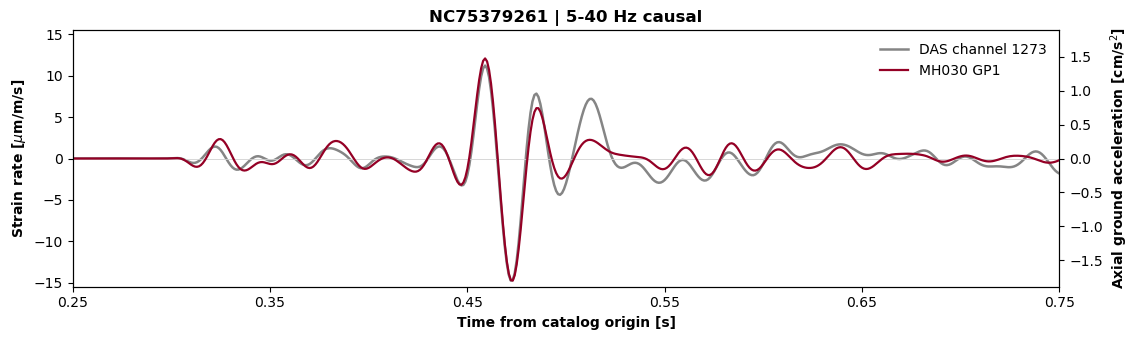

Saved: results/das_geophone_common_workflow/NC75379261/NC75379261_physical_ch1693.8_broadband.png


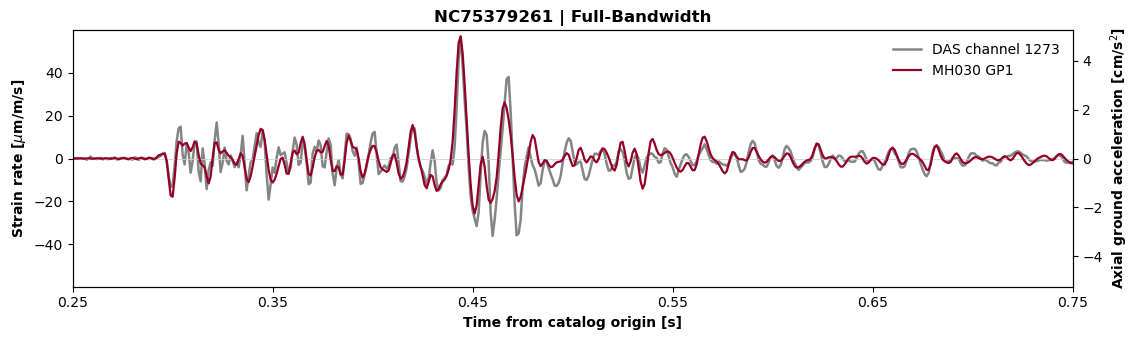


Amplitude QC
------------
DAS broadband peak: 56.8938 um/m/s
DAS 5-40 causal peak: 14.7453 um/m/s
GP1 broadband peak: 4.99478 cm/s^2
GP1 5-40 causal peak: 1.80166 cm/s^2


In [49]:
# =============================================================================
# 4. Plot comparisons
# =============================================================================

def make_plot(
    das_trace,
    geo_trace,
    title,
    filename,
):
    mask = (
        (DAS_time_s >= PLOT_TMIN_S)
        & (DAS_time_s <= PLOT_TMAX_S)
    )

    t = DAS_time_s[mask]
    d = das_trace[mask]
    g = geo_trace[mask]

    fig, ax1 = plt.subplots(
        figsize=(11.5, 3.5)
    )

    line_das, = ax1.plot(
        t,
        d,
        color=DAS_COLOR,
        lw=1.8,
        label=f"DAS channel {DAS_DATA_ROW}",
    )

    ax2 = ax1.twinx()

    line_geo, = ax2.plot(
        t,
        g,
        color=GEO_COLOR,
        lw=1.6,
        label="MH030 GP1",
    )

    ax1.axhline(
        0.0,
        color="0.82",
        lw=0.6,
    )

    ax1.set_xlim(
        PLOT_TMIN_S,
        PLOT_TMAX_S,
    )

    ax1.set_xticks(
        np.arange(
            PLOT_TMIN_S,
            PLOT_TMAX_S + 0.5 * XTICK_STEP_S,
            XTICK_STEP_S,
        )
    )

    ax1.set_xlabel(
        "Time from catalog origin [s]",
        fontweight="bold",
    )

    ax1.set_ylabel(
        r"Strain rate [$\mu$m/m/s]",
        fontweight="bold",
    )

    ax2.set_ylabel(
        r"Axial ground acceleration [cm/s$^2$]",
        fontweight="bold",
    )

    symmetric_ylim(
        ax1,
        d,
    )

    symmetric_ylim(
        ax2,
        g,
    )

    ax1.legend(
        [line_das, line_geo],
        [line_das.get_label(), line_geo.get_label()],
        frameon=False,
        loc="upper right",
    )

    ax1.set_title(
        title,
        fontweight="bold",
    )

    fig.tight_layout()

    if SAVE_FIGURES:
        path = OUTPUT_DIR / filename
        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight",
        )
        print("Saved:", path)

    plt.show()


# 5-40 Hz causal / non-zero-phase
make_plot(
    das_causal,
    acceleration_causal_cm_s2,
    (
        f"{EVENT_ID} | "
        f"{FMIN_HZ:g}-{FMAX_HZ:g} Hz causal"
    ),
    (
        f"{EVENT_ID}_physical_ch"
        f"{MATCHED_REFERENCE_CHANNEL:.1f}_"
        f"{FMIN_HZ:g}_{FMAX_HZ:g}Hz_causal.png"
    ),
)


# Broadband: response removed, no final science bandpass
make_plot(
    das_full,
    acceleration_full_cm_s2,
    (
        f"{EVENT_ID} | "
        "Full-Bandwidth"
    ),
    (
        f"{EVENT_ID}_physical_ch"
        f"{MATCHED_REFERENCE_CHANNEL:.1f}_"
        "broadband.png"
    ),
)


# Numerical QC in the displayed window.
qc = (
    (DAS_time_s >= PLOT_TMIN_S)
    & (DAS_time_s <= PLOT_TMAX_S)
)

print()
print("Amplitude QC")
print("------------")
print(
    "DAS broadband peak:",
    f"{np.max(np.abs(das_full[qc])):.6g} um/m/s",
)
print(
    "DAS 5-40 causal peak:",
    f"{np.max(np.abs(das_causal[qc])):.6g} um/m/s",
)
print(
    "GP1 broadband peak:",
    f"{np.max(np.abs(acceleration_full_cm_s2[qc])):.6g} cm/s^2",
)
print(
    "GP1 5-40 causal peak:",
    f"{np.max(np.abs(acceleration_causal_cm_s2[qc])):.6g} cm/s^2",
)
